<a href="https://colab.research.google.com/github/shirohigexe/practicas_HO_ML/blob/main/Ecommerce.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Librerias

In [86]:
#Basicos
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from IPython.display import display, HTML

#Modelos
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

#Extraccion y exploracion de datos

In [49]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Path to dataset files: /kaggle/input/brazilian-ecommerce


In [50]:


costumers = pd.read_csv(path + "/olist_customers_dataset.csv")
geolocation = pd.read_csv(path + "/olist_geolocation_dataset.csv")
items = pd.read_csv(path + "/olist_order_items_dataset.csv")
payments = pd.read_csv(path + "/olist_order_payments_dataset.csv")
reviews = pd.read_csv(path + "/olist_order_reviews_dataset.csv")
orders = pd.read_csv(path + "/olist_orders_dataset.csv")
products = pd.read_csv(path + "/olist_products_dataset.csv")
sellers = pd.read_csv(path + "/olist_sellers_dataset.csv")
category = pd.read_csv(path + "/product_category_name_translation.csv")

In [51]:



datasets = {
    "Customers": costumers,
    "Geolocation": geolocation,
    "Order Items": items,
    "Order Payments": payments,
    "Order Reviews": reviews,
    "Orders": orders,
    "Products": products,
    "Sellers": sellers,
    "Category Translation": category
}

for name, df in datasets.items():
    display(HTML(f"<h3>Dataset: {name} ({df.shape[0]} filas, {df.shape[1]} columnas)</h3>"))
    display(df.head(2))
    display(HTML("<hr>"))

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories


## Union de datos
Unimos varias tablas para poder entrenar los dos modelos de forma clara y eficiente, basandonos en las relaciones de las tablas
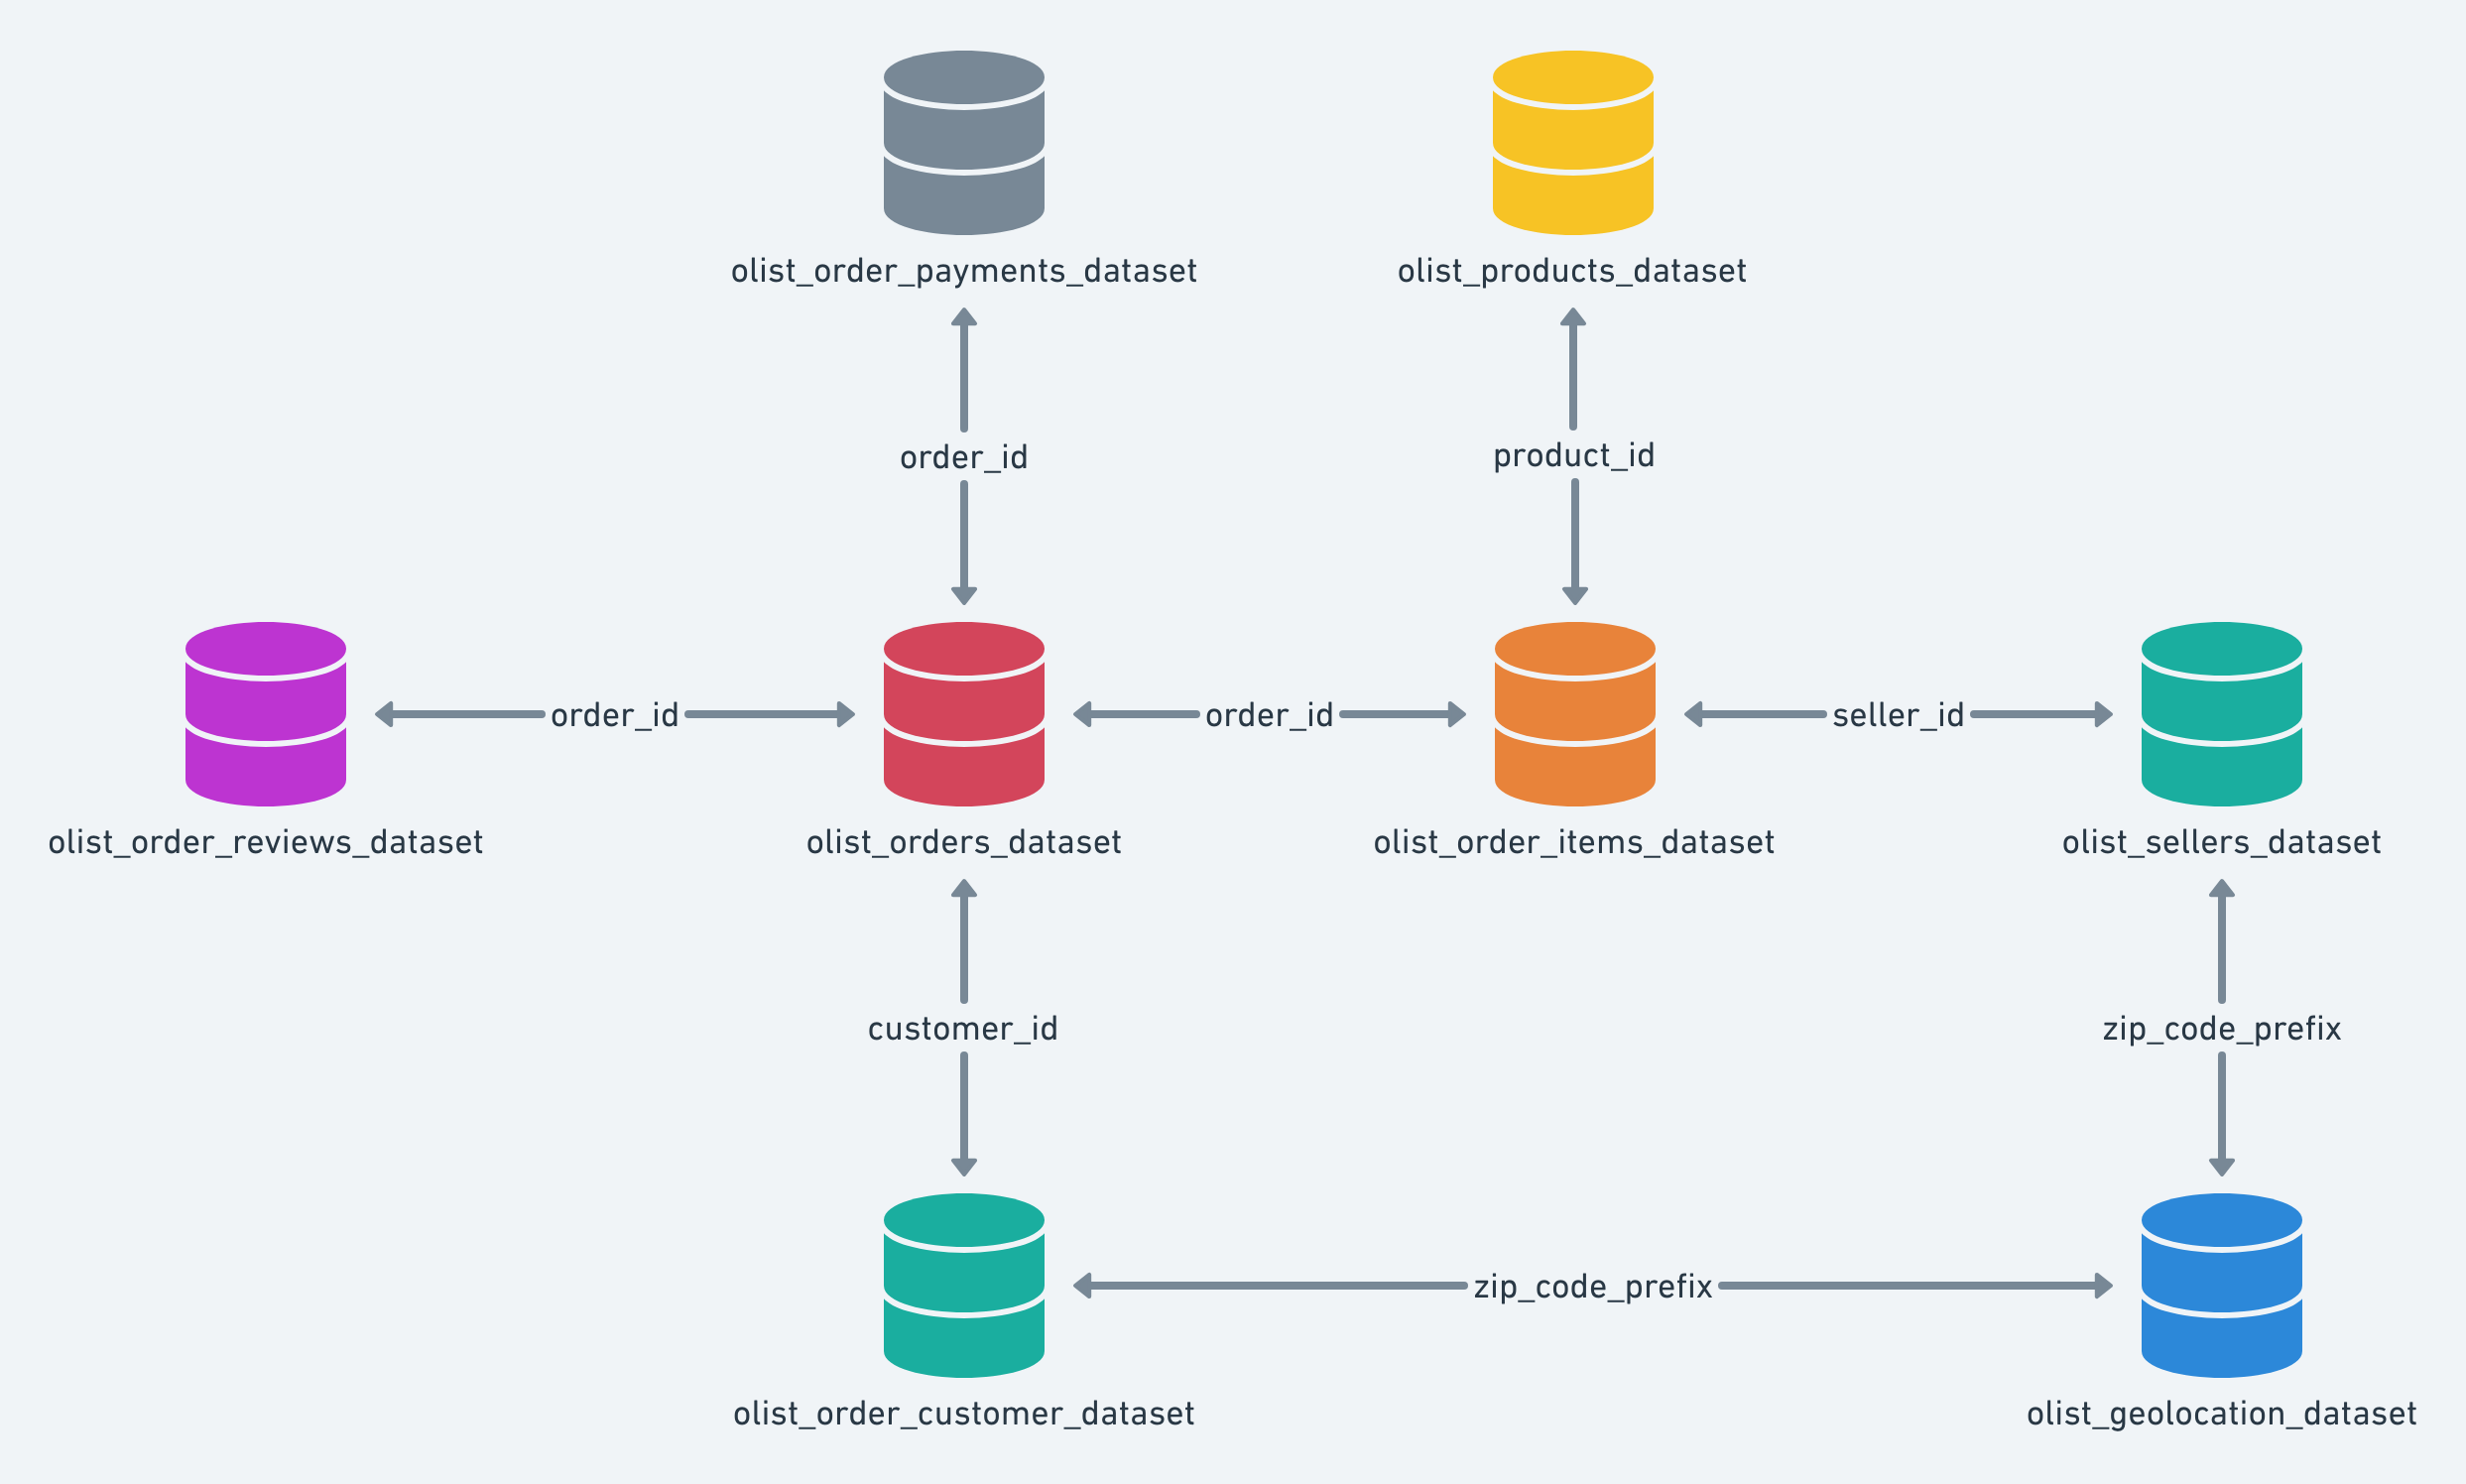

### DF Clustering


In [52]:
costumers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [53]:
costumers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [54]:
geolocation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


In [55]:
geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


Existe una diferencia grandisima en la cantidad de datos debido a que los datos de geolocalización se multiplican gracias a que varios regustros pertenecen a un codigo postal.<br>
Esto puede crear un problema de multiplicación de datos, para prevenir esto, agruparemos por codigo postal y luego usaremos la media de la latud y longitud para borrar estos registros repetidos y facilitar el clustering.<br>
Además se añade variación aleatoria (basada en una distribución normal) a las coordenadas promediadas.

In [56]:
# 1. Agrupar la geolocalización para tener un único registro por código postal
geo_unique = geolocation.groupby('geolocation_zip_code_prefix').agg({
    'geolocation_lat': 'mean',
    'geolocation_lng': 'mean',
    'geolocation_city': 'first',      # Tomamos la primera ciudad registrada
    'geolocation_state': 'first'     # Tomamos el primer estado registrado
}).reset_index()


In [76]:
geo_cost0 = pd.merge(costumers, geo_unique, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left')

geo_cost0.drop('geolocation_zip_code_prefix', axis=1, inplace=True)

también, parta mayor facilidad y una simulación apegada a la realidad de una servicio de paqueteria, nos centraremos en una unca ciudad, en este caso, ecogeremos la ciudad que más registros tenga

In [77]:
cities = geo_cost0['geolocation_city'].unique()

In [78]:
Max = 0
x = ''
for city in cities:
    if len(geo_cost0[geo_cost0['geolocation_city']==city]) > Max:
        Max = len(geo_cost0[geo_cost0['geolocation_city']==city])
        x = city
print(x, ':', Max)


sao paulo : 13207


In [79]:
geo_cost = geo_cost0[geo_cost0['geolocation_city']=='sao paulo']
geo_cost.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13207 entries, 2 to 99423
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               13207 non-null  object 
 1   customer_unique_id        13207 non-null  object 
 2   customer_zip_code_prefix  13207 non-null  int64  
 3   customer_city             13207 non-null  object 
 4   customer_state            13207 non-null  object 
 5   geolocation_lat           13207 non-null  float64
 6   geolocation_lng           13207 non-null  float64
 7   geolocation_city          13207 non-null  object 
 8   geolocation_state         13207 non-null  object 
dtypes: float64(2), int64(1), object(6)
memory usage: 1.0+ MB


In [80]:
geo_cost

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,-23.531642,-46.656289,sao paulo,SP
6,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,sao paulo,SP,-23.584221,-46.674053,sao paulo,SP
13,eabebad39a88bb6f5b52376faec28612,295c05e81917928d76245e842748184d,5704,sao paulo,SP,-23.628926,-46.720175,sao paulo,SP
18,9b8ce803689b3562defaad4613ef426f,7f3a72e8f988c6e735ba118d54f47458,5416,sao paulo,SP,-23.560949,-46.688422,sao paulo,SP
22,2938121a40a20953c43caa8c98787fcb,482441ea6a06b1f72fe9784756c0ea75,5713,sao paulo,SP,-23.626373,-46.730334,sao paulo,SP
...,...,...,...,...,...,...,...,...,...
99407,e98998055b4804137a020830903f93f2,e097d846931763789c3fd00b27f3c325,3057,sao paulo,SP,-23.541184,-46.596844,sao paulo,SP
99408,f6c6d3e1e20969a5eed982163f959719,fb354969e06f2093c0083cbfbb91864e,1521,sao paulo,SP,-23.561174,-46.621509,sao paulo,SP
99411,da37711b17efd5f2539e8196ab215f04,5f2971f9805e3ccb030226e30c8e8390,4313,sao paulo,SP,-23.637283,-46.638005,sao paulo,SP
99422,821a7275a08f32975caceff2e08ea262,046470763123d3d6364f89095b4e47ab,5734,sao paulo,SP,-23.625699,-46.743468,sao paulo,SP


In [81]:
'''

# Fijamos una semilla para que la simulación sea reproducible
np.random.seed(42)

# Definimos la dispersión: 0.003 grados representan unos ~330 metros de desviación estándar
dispersion = 0.003

# Añadimos ruido espacial usando una distribución normal (media 0, desviación 0.003)
geo_cost['latitud_simulada'] = geo_cost['geolocation_lat'] + np.random.normal(0, dispersion, len(geo_cost))
geo_cost['longitud_simulada'] = geo_cost['geolocation_lng'] + np.random.normal(0, dispersion, len(geo_cost))

geo_cost'''

"\n\n# Fijamos una semilla para que la simulación sea reproducible\nnp.random.seed(42)\n\n# Definimos la dispersión: 0.003 grados representan unos ~330 metros de desviación estándar\ndispersion = 0.003\n\n# Añadimos ruido espacial usando una distribución normal (media 0, desviación 0.003)\ngeo_cost['latitud_simulada'] = geo_cost['geolocation_lat'] + np.random.normal(0, dispersion, len(geo_cost))\ngeo_cost['longitud_simulada'] = geo_cost['geolocation_lng'] + np.random.normal(0, dispersion, len(geo_cost))\n\ngeo_cost"

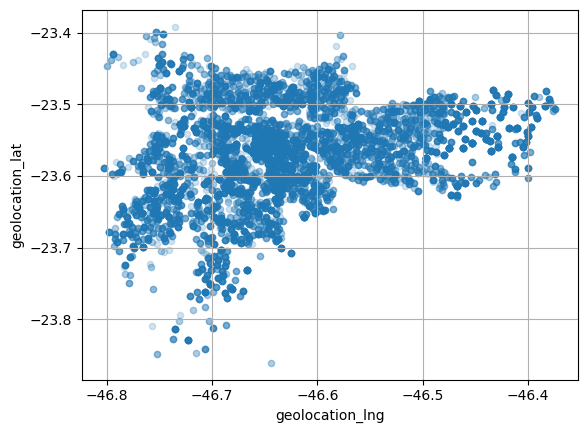

In [82]:
geo_cost.plot(kind="scatter", x="geolocation_lng", y="geolocation_lat", grid=True, alpha=0.2)

plt.show()

Bajo este enfoque, mediante k-Means, detectaré la cantidad de zonas mas matematicamente eficientes y saber la cantidad de furgones que debo contratar.

Desidí usar k-means porque a diferencia de DBSCAN, toma en cuenta los outliers, cosa que nos beneficia como empresa ya que toma en cuenta paquetes que se deben entregar a 'bordes' de la ciudad.

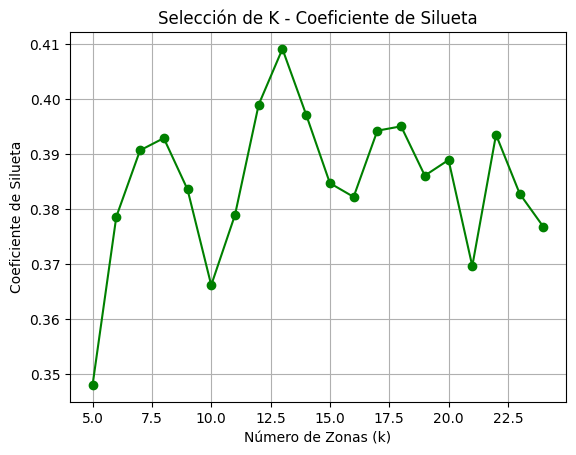

In [87]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

coordenadas = geo_cost[['geolocation_lng','geolocation_lat']]
puntuaciones_silueta = []
rango_k = range(5, 25) # estos pueden ser la cantidad de furgones disponibles para hacer las entregas



for k in rango_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init='auto')
    etiquetas = modelo.fit_predict(coordenadas)

    # Calcular el score
    score = silhouette_score(coordenadas, etiquetas)
    puntuaciones_silueta.append(score)


plt.plot(rango_k, puntuaciones_silueta, marker='o')
plt.xlabel('Número de Zonas (k)')
plt.ylabel('Coeficiente de Silueta')
plt.title('Selección de K - Coeficiente de Silueta')
plt.grid(True)
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but KMeans was fitted with feature names



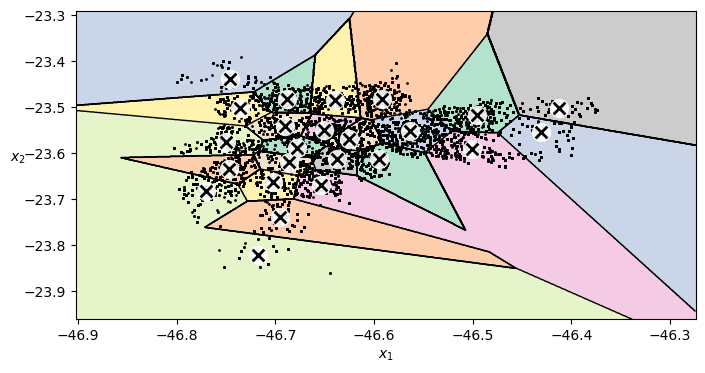

In [92]:
'''Codigo sacado de Hands on Machine Learning with scikit-learn & Pytorch'''

def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=35, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=12,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    # Es necesario predecir sobre un array plano de coordenadas
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                cmap="Pastel2")
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                linewidths=1, colors='k')
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("$x_1$")
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", rotation=0)
    else:
        plt.tick_params(labelleft=False)

plt.figure(figsize=(8, 4))
# Pasamos 'coordenadas.values' (que solo tiene las columnas del modelo) convertido en array de NumPy para evitar el error de Pandas
plot_decision_boundaries(modelo, coordenadas[['geolocation_lng', 'geolocation_lat']].values)

plt.show()